# Báo Cáo Khảo Sát & Trực Quan Hóa Dữ Liệu Thị Giác Màu CIFAR-10
**Môn học:** Phát Triển Hệ Thống Thông Minh (Intelligent System Development)  
**Bài tập 04:** Khám phá & Trực quan hóa dữ liệu ảnh màu đa kênh (RGB) trước khi huấn luyện mô hình mạng nơ-ron

---

### Mục tiêu khảo sát:
1. **Khảo sát cấu trúc & độ cân bằng lớp:** Xác minh phân phối hoàn hảo của 10 lớp đối tượng thế giới thực (máy bay, ô tô, chim, mèo, hươu, chó, ếch, ngựa, tàu thủy, xe tải) trên 50,000 ảnh train và 10,000 ảnh test.
2. **Thư viện mẫu thực tế đa dạng:** Trưng bày lưới 100 ảnh mẫu (10 lớp × 10 mẫu) để đánh giá các thách thức thị giác thực tế: góc chụp, bối cảnh phức tạp, ánh sáng và tư thế.
3. **Phân tích tách kênh màu (RGB Decomposition):** Tách ảnh màu thành 3 kênh Đỏ (Red), Lục (Green), Lam (Blue) để hiểu cách thông tin màu sắc phân bổ theo từng nhóm lớp (ví dụ: kênh Lam chiếm ưu thế ở máy bay và tàu thủy; kênh Lục ở ếch và hươu).
4. **Ảnh nguyên mẫu trung bình & biến thiên nền (Background Biases):** Khảo sát ảnh trung bình của từng lớp để phát hiện bối cảnh môi trường đặc trưng (bầu trời xanh, mặt đường nhựa, thảm cỏ).
5. **Giảm chiều đặc trưng không gian đa chiều (PCA 2D):** Khảo sát sự phân tách vĩ mô giữa hai siêu nhóm: **Phương tiện cơ giới (Vehicles)** và **Động vật tự nhiên (Animals)**.


In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA

# Cấu hình hạt giống ngẫu nhiên để tái lập thực nghiệm
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Cấu hình giao diện biểu đồ chuyên nghiệp
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

# Thiết lập thư mục lưu trữ biểu đồ báo cáo
FIGURES_DIR = '../reports/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
print(f"Môi trường đồ họa sẵn sàng. Thư mục lưu biểu đồ: {FIGURES_DIR}")


Môi trường đồ họa sẵn sàng. Thư mục lưu biểu đồ: ../reports/figures


### 1. Nạp Dữ Liệu & Danh Mục 10 Nhãn Đối Tượng
Tập CIFAR-10 gồm 10 lớp đối tượng riêng biệt. Dữ liệu được nạp từ mảng nén `cifar10.npz` (chứa các mảng ảnh 32×32×3) đồng thời đối chiếu với các file ảnh raw `.png` trong thư mục `../data/train/` và `../data/test/`.


In [2]:
# Đường dẫn dữ liệu
DATA_NPZ = '../data/cifar10.npz'
TRAIN_DIR = '../data/train'
TEST_DIR = '../data/test'

if not os.path.exists(DATA_NPZ):
    DATA_NPZ = 'src/Assigment 04/cifar10/data/cifar10.npz'
    TRAIN_DIR = 'src/Assigment 04/cifar10/data/train'
    TEST_DIR = 'src/Assigment 04/cifar10/data/test'

# Nạp mảng dữ liệu nén
data = np.load(DATA_NPZ)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# Tên 10 lớp chuẩn của CIFAR-10
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
CLASS_NAMES_VN = ['Máy bay', 'Ô tô', 'Chim', 'Mèo', 'Hươu',
                  'Chó', 'Ếch', 'Ngựa', 'Tàu thủy', 'Xe tải']

print(f"Tập huấn luyện X_train: {X_train.shape} (dtype: {X_train.dtype})")
print(f"Nhãn huấn luyện y_train: {y_train.shape} (dtype: {y_train.dtype})")
print(f"Tập kiểm thử X_test:    {X_test.shape} (dtype: {X_test.dtype})")
print(f"Nhãn kiểm thử y_test:   {y_test.shape} (dtype: {y_test.dtype})")
print(f"Dải giá trị pixel RGB:  [{X_train.min()}, {X_train.max()}]")

# Kiểm tra thư mục ảnh raw PNG
train_png_count = sum(len(files) for _, _, files in os.walk(TRAIN_DIR) if any(f.endswith('.png') for f in files))
test_png_count = sum(len(files) for _, _, files in os.walk(TEST_DIR) if any(f.endswith('.png') for f in files))
print(f"Số lượng file ảnh raw .png: {train_png_count:,} ảnh train, {test_png_count:,} ảnh test.")


Tập huấn luyện X_train: (50000, 32, 32, 3) (dtype: uint8)
Nhãn huấn luyện y_train: (50000,) (dtype: int64)
Tập kiểm thử X_test:    (10000, 32, 32, 3) (dtype: uint8)
Nhãn kiểm thử y_test:   (10000,) (dtype: int64)
Dải giá trị pixel RGB:  [0, 255]


Số lượng file ảnh raw .png: 50,000 ảnh train, 10,000 ảnh test.


### 2. Kiểm Toán Độ Cân Bằng Lớp (Class Balance)
CIFAR-10 được thiết kế hoàn hảo với số lượng mẫu mỗi lớp hoàn toàn bằng nhau.


,Lớp Tiếng Anh,Tên Tiếng Việt,Số lượng Train,Tỉ lệ Train (%),Số lượng Test,Tỉ lệ Test (%)
0,airplane,Máy bay,5000,10.0,1000,10.0
1,automobile,Ô tô,5000,10.0,1000,10.0
2,bird,Chim,5000,10.0,1000,10.0
3,cat,Mèo,5000,10.0,1000,10.0
4,deer,Hươu,5000,10.0,1000,10.0
5,dog,Chó,5000,10.0,1000,10.0
6,frog,Ếch,5000,10.0,1000,10.0
7,horse,Ngựa,5000,10.0,1000,10.0
8,ship,Tàu thủy,5000,10.0,1000,10.0
9,truck,Xe tải,5000,10.0,1000,10.0


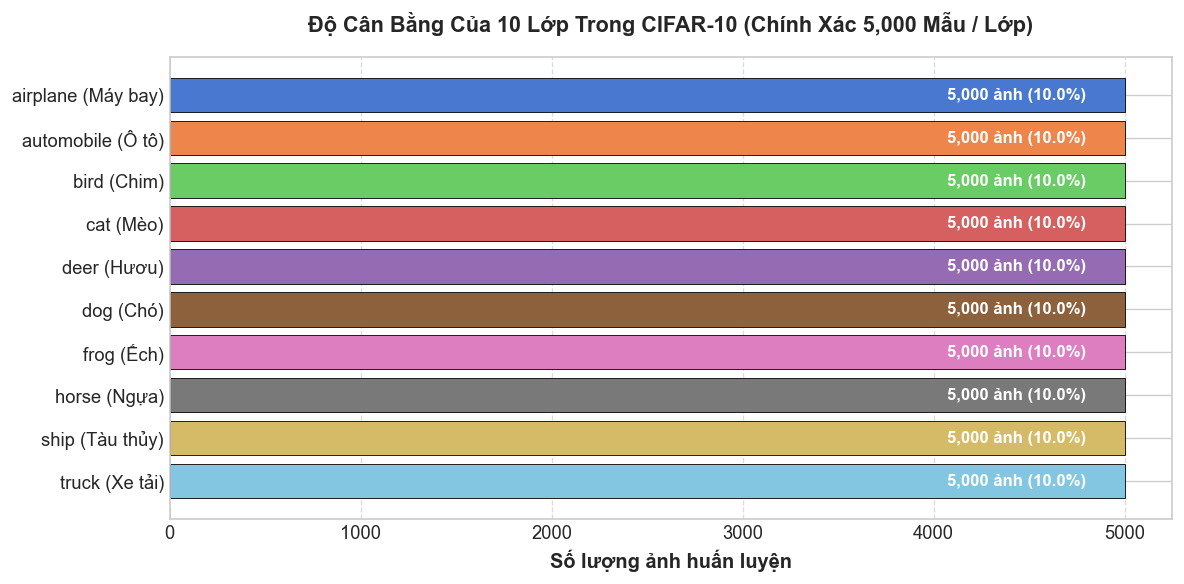

Đã lưu biểu đồ: ../reports/figures/fig_01_cifar10_class_distribution.png


In [3]:
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

df_dist = pd.DataFrame({
    'Lớp Tiếng Anh': CLASS_NAMES,
    'Tên Tiếng Việt': CLASS_NAMES_VN,
    'Số lượng Train': train_counts.values,
    'Tỉ lệ Train (%)': (train_counts.values / len(y_train) * 100).round(1),
    'Số lượng Test': test_counts.values,
    'Tỉ lệ Test (%)': (test_counts.values / len(y_test) * 100).round(1)
})
display(df_dist)

# Biểu đồ thanh ngang thể hiện sự cân bằng hoàn hảo
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(CLASS_NAMES))
colors = sns.color_palette("muted", 10)

bars = ax.barh(y_pos, train_counts.values, color=colors, edgecolor='black', linewidth=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{en} ({vn})" for en, vn in zip(CLASS_NAMES, CLASS_NAMES_VN)], fontsize=11)
ax.invert_yaxis()
ax.set_xlabel('Số lượng ảnh huấn luyện', fontsize=12, fontweight='bold')
ax.set_title('Độ Cân Bằng Của 10 Lớp Trong CIFAR-10 (Chính Xác 5,000 Mẫu / Lớp)', fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:,} ảnh (10.0%)', xy=(w - 200, bar.get_y() + bar.get_height()/2),
                ha='right', va='center', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_01_cifar10_class_distribution.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")


### 3. Thư Viện Mẫu Thực Tế (10 Lớp × 10 Biến Thể)
Hiển thị 100 ảnh mẫu ngẫu nhiên từ tập dữ liệu. Mỗi hàng đại diện cho 1 lớp đối tượng, thể hiện rõ các góc chụp, tỉ lệ kích thước và độ phân giải 32×32 pixel.


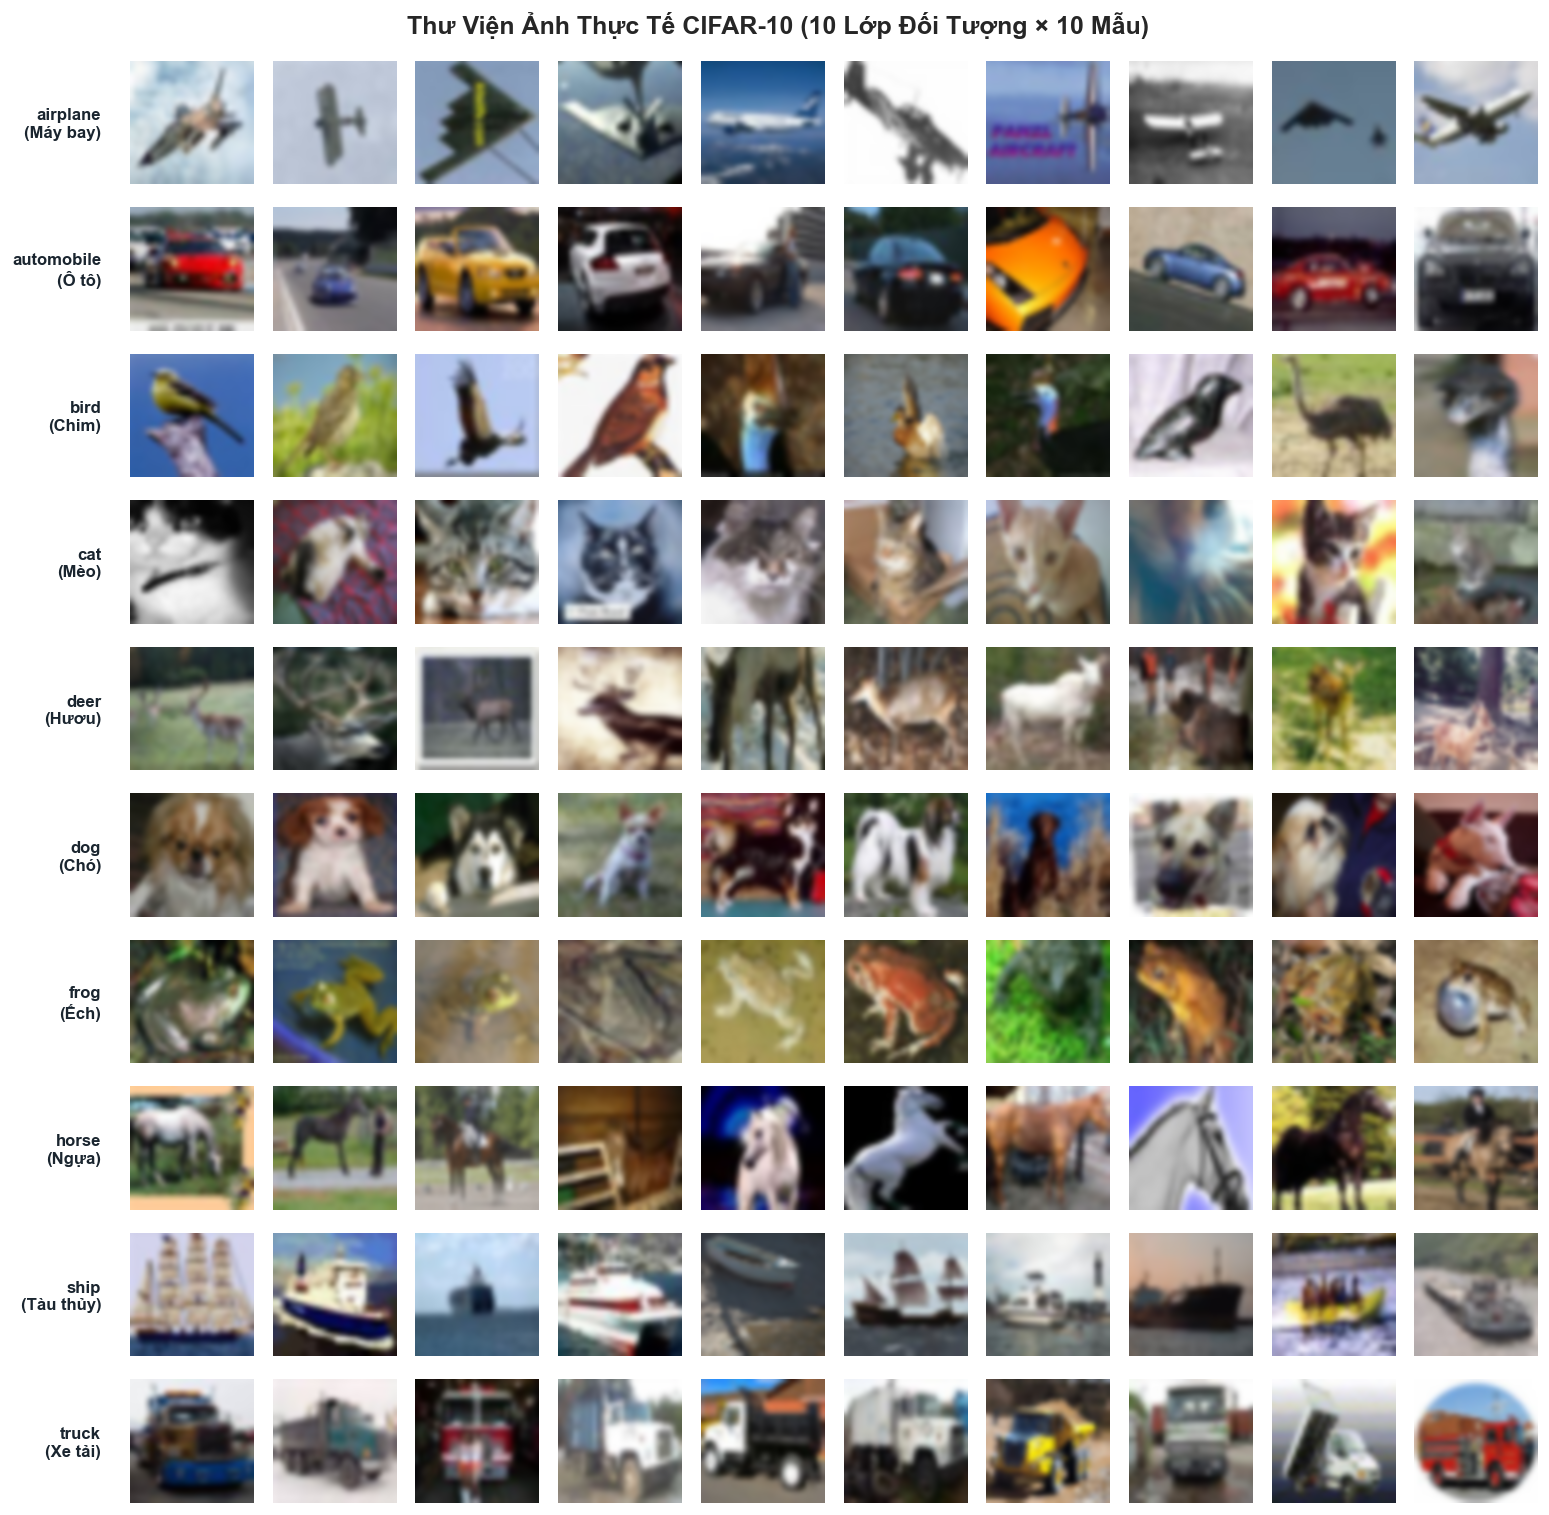

Đã lưu biểu đồ: ../reports/figures/fig_02_cifar10_sample_grid.png


In [4]:
fig, axes = plt.subplots(10, 10, figsize=(13, 13))

for c_idx in range(10):
    class_indices = np.where(y_train == c_idx)[0]
    sample_indices = np.random.choice(class_indices, size=10, replace=False)
    
    for col, idx in enumerate(sample_indices):
        ax = axes[c_idx, col]
        ax.imshow(X_train[idx], interpolation='bicubic')
        ax.axis('off')
        
        if col == 0:
            ax.text(-8, 16, f"{CLASS_NAMES[c_idx]}\n({CLASS_NAMES_VN[c_idx]})",
                    fontsize=10, fontweight='bold', va='center', ha='right', color='#1a252f')

plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.suptitle('Thư Viện Ảnh Thực Tế CIFAR-10 (10 Lớp Đối Tượng × 10 Mẫu)', fontsize=15, fontweight='bold', y=0.97)
fig_path = os.path.join(FIGURES_DIR, 'fig_02_cifar10_sample_grid.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")
